In [1]:
import sys 
sys.path.append("..") 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

from src.data_loader import load_data 

df = load_data() 
df.head() 

INFO:src.data_loader:Data loaded successfully: 12000 rows, 18 columns


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Converted
0,1,14.6517,0,0.0000,19,283.8812,0.008014,0.042106,68.579222,0.0,June,1,2,1,1,Returning_Visitor,False,1
1,1,18.9189,2,54.9802,15,1241.7638,0.032395,0.058101,0.000000,0.0,May,2,1,8,12,Returning_Visitor,False,0
2,1,30.0198,0,0.0000,23,365.3384,0.006802,0.029451,0.000000,0.0,Mar,1,2,1,3,New_Visitor,True,0
3,1,6.5566,0,0.0000,6,687.4788,0.039577,0.104395,0.000000,0.6,Dec,1,1,1,2,Returning_Visitor,True,0
4,1,112.5842,1,36.3523,19,656.4535,0.004594,0.038321,0.000000,0.0,Mar,2,1,2,5,Returning_Visitor,False,0


## 1. Conversion Rate Analysis

Checking the overall conversion rate — what percentage of sessions resulted in a purchase.

In [2]:
conversion_rate = df["Converted"].mean() * 100 
print(f"Overall conversion rate: {conversion_rate:.2f}%") 

df["Converted"].value_counts() 

Overall conversion rate: 15.72%


Converted
0    10114
1     1886
Name: count, dtype: int64

**Insight:** The dataset is highly imbalanced — only 15.72% of sessions (1,886 out of 12,000) resulted in a purchase. This confirms accuracy will be a misleading metric; PR-AUC and recall will be prioritized during model evaluation, and class imbalance handling (SMOTE/class_weight) will be needed.

## 2. Buyer vs Non-Buyer Behavior

Comparing average behavior metrics between converted and non-converted sessions to see what differentiates buyers.

In [3]:
df.groupby("Converted")[["PageValues", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates"]].mean()

,PageValues,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
Converted,,,,,
0,5.081279,17.113902,624.718320,0.023238,0.058432
1,50.562025,34.408802,1250.669958,0.010391,0.030894


**Insight:** PageValues is by far the strongest differentiator — buyers show ~10x higher average PageValues (50.6 vs 5.1) than non-buyers. Buyers also browse roughly 2x more product pages and spend 2x longer on them, with lower bounce and exit rates. This aligns with intuition (engaged visitors convert more) and confirms PageValues will likely be one of the most important features — but its leakage risk (per the PRD) needs to be evaluated before using it in the model.

## 3. Seasonality — Conversion Rate by Month

Checking if conversion rate varies across months, which could indicate shopping seasons (e.g., holiday months).

In [4]:
monthly_conversion = df.groupby("Month")["Converted"].mean().sort_values(ascending=False) * 100
monthly_conversion

Month
Nov     20.000000
Dec     17.942584
May     17.079347
Mar     13.873106
Oct     13.649025
Aug     12.830189
Jul     12.500000
Sep     11.833333
Feb     10.079576
June     9.866221
Name: Converted, dtype: float64

**Insight:** Conversion rate varies significantly by month, peaking in November (20.0%) and December (17.9%) — consistent with holiday shopping season. May also shows a notably higher rate (17.1%), possibly tied to another sale event. June has the lowest conversion (9.9%). Only 10 of 12 months appear in the data — verification confirmed Jan and April have zero sessions entirely, with counts ranging from May at 3,554 sessions down to Feb at 377. This looks like a data collection gap rather than a business pattern. Month will be a useful categorical feature for the model, but the model will need to handle unseen month categories (Jan, April) at prediction time.

## 4. Conversion by Visitor Type

Checking if new visitors, returning visitors, and "other" visitors convert at different rates.

In [5]:
visitor_conversion = df.groupby("VisitorType")["Converted"].agg(["mean","count"]) 
visitor_conversion["mean"] = visitor_conversion["mean"] * 100 
visitor_conversion 

,mean,count
VisitorType,,
New_Visitor,10.166240,1564
Other,15.037594,133
Returning_Visitor,16.567990,10303


**Insight:** Returning visitors convert at a notably higher rate (16.6%) than new visitors (10.2%), consistent with the intuition that trust and familiarity drive purchases. Returning visitors also make up the vast majority of the dataset (10,303 of 12,000 sessions), so this estimate is reliable. The "Other" category shows a similar rate to returning visitors (15.0%) but only has 133 sessions — too small a sample to draw strong conclusions from. VisitorType looks like a useful categorical feature.

## 5. Visualizing Monthly Conversion Rate

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


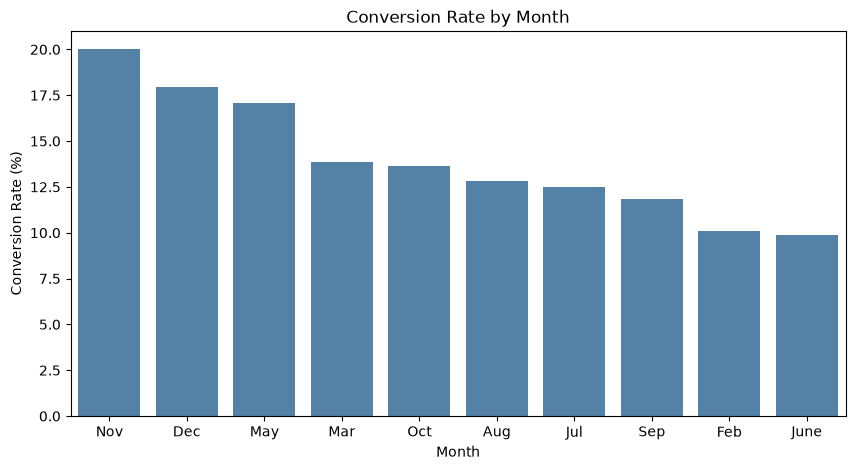

In [6]:
plt.figure(figsize=(10,5)) 
sns.barplot(x=monthly_conversion.index, y=monthly_conversion.values, color="steelblue") 
plt.title("Conversion Rate by Month") 
plt.xlabel("Month") 
plt.ylabel("Conversion Rate (%)") 
plt.show() 

**Insight:** The chart visually confirms the holiday-season effect — November and December stand out clearly above the rest, with a steady decline through the rest of the year down to June. This visual pattern makes the seasonality trend much easier to communicate than the raw numbers alone.

## 6. Interactive Chart — Conversion Rate by Month (Plotly)

In [7]:
import plotly.express as px
fig = px.bar( 
    x = monthly_conversion.index, 
    y = monthly_conversion.values, 
    labels = {"x": "Month", "y": "Conversion Rate (%)"}, 
    title = "Conversion Rate by Month (Interactive)"
) 
fig.show() 


**Insight:** The interactive Plotly version shows the same monthly pattern as the static chart, but allows hovering over each bar to see exact conversion rate values — useful for deeper exploration when this analysis is shared in a dashboard later.

## 7. Data Quality Checks — Missing Values & Duplicates

In [8]:
print("Missing values per column:") 
print(df.isnull().sum()) 
print("\nTotal duplicate rows:", df.duplicated().sum()) 

Missing values per column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Converted                  0
dtype: int64

Total duplicate rows: 0


**Insight:** The dataset is clean — no missing values across any of the 18 columns, and no duplicate rows. This simplifies preprocessing significantly; no imputation strategy or deduplication step will be needed.

## 8. Distribution Check — Skewed Numeric Features

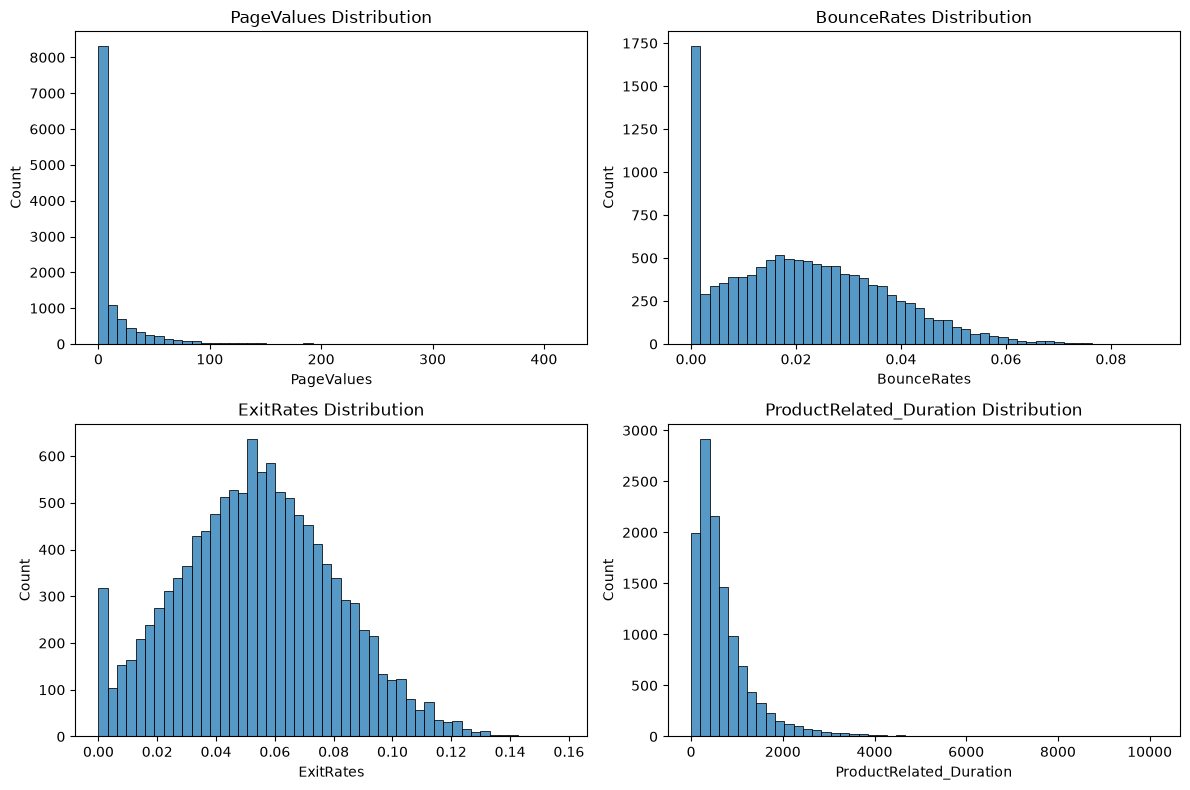

In [9]:
fig, axes = plt.subplots(2,2,figsize =(12,8)) 

sns.histplot(df["PageValues"], bins = 50, ax = axes[0,0]) 
axes[0,0].set_title("PageValues Distribution") 

sns.histplot(df["BounceRates"], bins = 50, ax = axes[0,1]) 
axes[0,1].set_title("BounceRates Distribution") 

sns.histplot(df["ExitRates"], bins = 50, ax = axes[1,0]) 
axes[1,0].set_title("ExitRates Distribution") 

sns.histplot(df["ProductRelated_Duration"], bins = 50, ax = axes[1,1]) 
axes[1,1].set_title("ProductRelated_Duration Distribution") 

plt.tight_layout() 
plt.show() 


**Insight:** PageValues, BounceRates, and ProductRelated_Duration are all strongly right-skewed — most sessions cluster near zero with a long tail of extreme values. ExitRates is less skewed, closer to a mild bell shape with a slight tail. This confirms the earlier decision (in config.yaml) to apply log1p/RobustScaler transforms to these columns during preprocessing, since raw skewed values can hurt models like Logistic Regression that assume more normally-distributed inputs.